In [8]:
!pip install gymnasium -q

import random
from collections import deque
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [9]:
ENV_NAME = "CartPole-v1"
GAMMA = 0.99  # Discount factor
LR = 1e-3  # Learning rate
BATCH_SIZE = 64  # Replay batch size
BUFFER_CAPACITY = 10000  # Max replay memory capacity
EPSILON_START = 1.0  # Initial exploration rate
EPSILON_END = 0.01  # Minimum exploration rate
EPSILON_DECAY = 0.995  # Decay rate per episode
TARGET_UPDATE = 10  # Sync target network every N episodes
NUM_EPISODES = 500 # Total training episodes

In [10]:
class QNetwork(nn.Module):

    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim),
        )

    def forward(self, x):
        return self.net(x)

In [11]:
class ReplayBuffer:

    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        state, action, reward, next_state, done = zip(
            *random.sample(self.buffer, batch_size)
        )
        return (
            torch.FloatTensor(np.array(state)).to(device),
            torch.LongTensor(action).to(device),
            torch.FloatTensor(reward).to(device),
            torch.FloatTensor(np.array(next_state)).to(device),
            torch.FloatTensor(done).to(device),
        )

    def __len__(self):
        return len(self.buffer)

In [12]:
class DQNAgent:

    def __init__(self, state_dim, action_dim):
        self.action_dim = action_dim
        self.policy_net = QNetwork(state_dim, action_dim).to(device)
        self.target_net = QNetwork(state_dim, action_dim).to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=LR)
        self.loss_fn = nn.MSELoss()
        self.epsilon = EPSILON_START

    def select_action(self, state):
        # Epsilon-greedy action selection
        if random.random() < self.epsilon:
            return random.randint(0, self.action_dim - 1)
        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
        with torch.no_grad():
            return self.policy_net(state_tensor).argmax().item()

    def train_step(self, memory):
        if len(memory) < BATCH_SIZE:
            return

        states, actions, rewards, next_states, dones = memory.sample(
            BATCH_SIZE
        )

        # Q(s, a) estimates
        q_values = self.policy_net(states).gather(
            1, actions.unsqueeze(1)
        ).squeeze(1)

        # Target Q-values using Bellman equation
        with torch.no_grad():
            max_next_q = self.target_net(next_states).max(1)[0]
            target_q = rewards + GAMMA * max_next_q * (1 - dones)

        loss = self.loss_fn(q_values, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

    def update_target_network(self):
        self.target_net.load_state_dict(self.policy_net.state_dict())

    def update_epsilon(self):
        self.epsilon = max(EPSILON_END, self.epsilon * EPSILON_DECAY)

In [13]:
env = gym.make(ENV_NAME)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

agent = DQNAgent(state_dim, action_dim)
memory = ReplayBuffer(BUFFER_CAPACITY)

In [14]:
rewards_history = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    total_reward = 0
    done = False

    while not done:
        action = agent.select_action(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        memory.push(state, action, reward, next_state, done)
        agent.train_step(memory)

        state = next_state
        total_reward += reward

    agent.update_epsilon()

    # Periodically update target network weights
    if episode % TARGET_UPDATE == 0:
        agent.update_target_network()

    rewards_history.append(total_reward)

    if episode % 20 == 0:
        print(
            f"Episode {episode}/{NUM_EPISODES} | Total Reward: {total_reward} | Epsilon: {agent.epsilon:.2f}"
        )

env.close()

Episode 20/500 | Total Reward: 19.0 | Epsilon: 0.90
Episode 40/500 | Total Reward: 9.0 | Epsilon: 0.82
Episode 60/500 | Total Reward: 89.0 | Epsilon: 0.74
Episode 80/500 | Total Reward: 13.0 | Epsilon: 0.67
Episode 100/500 | Total Reward: 31.0 | Epsilon: 0.61
Episode 120/500 | Total Reward: 230.0 | Epsilon: 0.55
Episode 140/500 | Total Reward: 64.0 | Epsilon: 0.50
Episode 160/500 | Total Reward: 17.0 | Epsilon: 0.45
Episode 180/500 | Total Reward: 126.0 | Epsilon: 0.41
Episode 200/500 | Total Reward: 109.0 | Epsilon: 0.37
Episode 220/500 | Total Reward: 25.0 | Epsilon: 0.33
Episode 240/500 | Total Reward: 92.0 | Epsilon: 0.30
Episode 260/500 | Total Reward: 98.0 | Epsilon: 0.27
Episode 280/500 | Total Reward: 128.0 | Epsilon: 0.25
Episode 300/500 | Total Reward: 13.0 | Epsilon: 0.22
Episode 320/500 | Total Reward: 15.0 | Epsilon: 0.20
Episode 340/500 | Total Reward: 136.0 | Epsilon: 0.18
Episode 360/500 | Total Reward: 120.0 | Epsilon: 0.16
Episode 380/500 | Total Reward: 142.0 | Epsil

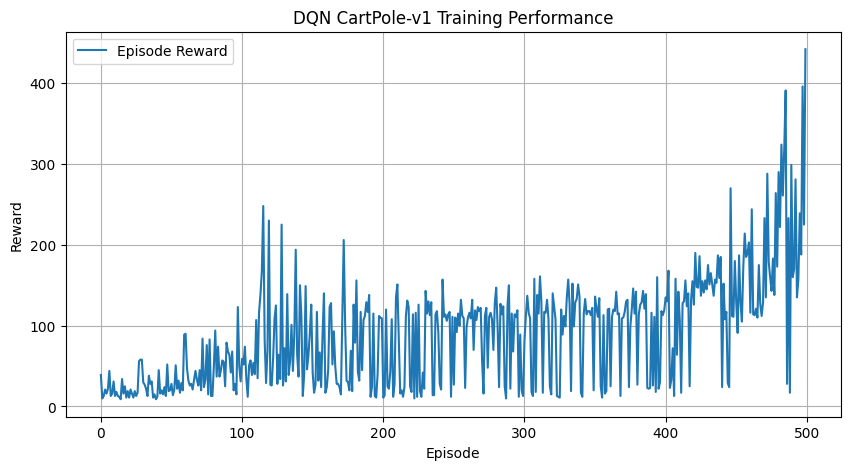

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(rewards_history, label="Episode Reward")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN CartPole-v1 Training Performance")
plt.grid(True)
plt.legend()
plt.show()